In [25]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score
import torch
import torch.nn as nn
print(torch.__version__)
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_recall_curve, roc_curve, roc_auc_score, average_precision_score
import matplotlib.pyplot as plt


2.8.0


In [5]:
columns = [
    "duration","protocol_type","service","flag","src_bytes","dst_bytes","land",
    "wrong_fragment","urgent","hot","num_failed_logins","logged_in","num_compromised",
    "root_shell","su_attempted","num_root","num_file_creations","num_shells",
    "num_access_files","num_outbound_cmds","is_host_login","is_guest_login","count",
    "srv_count","serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate",
    "same_srv_rate","diff_srv_rate","srv_diff_host_rate","dst_host_count",
    "dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate",
    "dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate",
    "label","difficulty"
]

In [6]:
df_train = pd.read_csv("../data/raw/KDDTrain+.txt", header=None, names=columns)
df_test = pd.read_csv("../data/raw/KDDTest+.txt", header=None, names=columns)
print(df_train.shape, df_test.shape)
datas = pd.DataFrame(df_train)
datas.head(5)

(125973, 43) (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [7]:
x_train = df_train.drop(["label", "difficulty"], axis = 1)
y_train = df_train["label"]
y_train_binary = (y_train != "normal").astype(int)
x_test = df_test.drop(["label", "difficulty"], axis = 1)
y_test = df_test["label"]
y_test_binary = (y_test != "normal").astype(int)

In [8]:
x_train_encoded = pd.get_dummies(x_train)
x_test_encoded = pd.get_dummies(x_test)
x_test_encoded = x_test_encoded.reindex(columns=x_train_encoded.columns, fill_value=0)
print(x_train_encoded.shape)
print(x_test_encoded.shape)


(125973, 122)
(22544, 122)


In [9]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train_encoded)
x_test_scaled = scaler.transform(x_test_encoded)
print(x_train_scaled.shape)
print(x_test_scaled.shape)

(125973, 122)
(22544, 122)


SyntaxError: invalid syntax (4046171615.py, line 1)

In [10]:
np.random.seed(42) # gives the same random sample everytime generated 
label_fraction = 0.05
n_samples = x_train_scaled.shape[0]
n_labeled = int(n_samples * label_fraction)
labeled_indices = np.random.choice(n_samples, size=n_labeled, replace=False)
is_labeled = np.zeros(n_samples, dtype=bool)
is_labeled[labeled_indices] = True

print(f"Total samples: {n_samples}")
print(f"Labeled samples: {is_labeled.sum()} ({is_labeled.sum()/n_samples:.1%})")
print(f"Unlabeled samples: {(~is_labeled).sum()} ({(~is_labeled).sum()/n_samples:.1%})")

Total samples: 125973
Labeled samples: 6298 (5.0%)
Unlabeled samples: 119675 (95.0%)


In [11]:
x_labeled = x_train_scaled[is_labeled]
y_labeled = y_train_binary[is_labeled]
y_unlabeled_true = y_train_binary[~is_labeled]
x_unlabeled = x_train_scaled[~is_labeled]

print(x_labeled.shape, y_labeled.shape)
print(x_unlabeled.shape, y_unlabeled_true.shape)

(6298, 122) (6298,)
(119675, 122) (119675,)


In [12]:
clf = LogisticRegression(max_iter = 1000, random_state=42)
clf.fit(x_labeled, y_labeled)

probs = clf.predict_proba(x_unlabeled)
attack_prob = probs[:, 1]
print(attack_prob[:10])

/Users/sayoowo5/CS4360-Senior-Experience-Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/sayoowo5/CS4360-Senior-Experience-Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/sayoowo5/CS4360-Senior-Experience-Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept


[0.00970282 0.06959076 0.99999959 0.00389487 0.01691357 0.99928081
 0.99999982 0.99999952 0.99999979 0.99999969]


/Users/sayoowo5/CS4360-Senior-Experience-Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/sayoowo5/CS4360-Senior-Experience-Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/sayoowo5/CS4360-Senior-Experience-Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: invalid value encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/sayoowo5/CS4360-Senior-Experience-Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sayoowo5/CS4360-Senior-Experience-Project/.venv/lib/python3.9/site-packag

In [13]:
high_threshold = .95
low_threshold = .05 
confident_attack = attack_prob >= high_threshold
confident_normal = attack_prob <= low_threshold
confident_mask = confident_attack | confident_normal

print(f"Confident predictions: {confident_mask.sum()} out of {len(attack_prob)} ({confident_mask.sum()/len(attack_prob):.1%})")
print(f"  - confident attack: {confident_attack.sum()}")
print(f"  - confident normal: {confident_normal.sum()}")

Confident predictions: 106816 out of 119675 (89.3%)
  - confident attack: 49829
  - confident normal: 56987


In [14]:
pseudo_labeles = np.where(confident_attack, 1,0)
pseudo_labels_confident = pseudo_labeles[confident_mask]
true_labels_confident = y_unlabeled_true[confident_mask]

accuracy = (pseudo_labels_confident == true_labels_confident).mean()
print(f"Pseudo-label accuracy on confident subset: {accuracy:.4f}")


Pseudo-label accuracy on confident subset: 0.9937


In [15]:
x_combined = np.vstack([x_labeled, x_unlabeled[confident_mask]])
y_combined = np.concatenate([y_labeled, pseudo_labels_confident])
print(x_combined.shape, y_combined.shape)
clf_self_trained = LogisticRegression(max_iter=1000, random_state=42)
clf_self_trained.fit(x_combined, y_combined)

y_pred_test = clf_self_trained.predict(x_test_scaled)

print(confusion_matrix(y_test_binary, y_pred_test))
print("Precision:", precision_score(y_test_binary, y_pred_test))
print("Recall:", recall_score(y_test_binary, y_pred_test))
print("F1 Score:", f1_score(y_test_binary, y_pred_test))





(113114, 122) (113114,)


/Users/sayoowo5/CS4360-Senior-Experience-Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/sayoowo5/CS4360-Senior-Experience-Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/sayoowo5/CS4360-Senior-Experience-Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/sayoowo5/CS4360-Senior-Experience-Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/sayoowo5/CS4360-Senior-Experience-Project/.venv/lib/python3.9/site-packages/sklearn/line

[[8983  728]
 [4945 7888]]
Precision: 0.9155060352831941
Recall: 0.6146653159822333
F1 Score: 0.7355121450883491


In [16]:
clf_baseline = LogisticRegression(max_iter = 1000, random_state=42)
clf_baseline.fit(x_labeled, y_labeled)
y_pred_baseline = clf_baseline.predict(x_test_scaled)
print(confusion_matrix(y_test_binary, y_pred_baseline))
print("Precision:", precision_score(y_test_binary, y_pred_baseline))
print("Recall:", recall_score(y_test_binary, y_pred_baseline))
print("F1 Score:", f1_score(y_test_binary, y_pred_baseline))


[[8995  716]
 [4897 7936]]
Precision: 0.9172445677300046
Recall: 0.6184056728746201
F1 Score: 0.7387479636956016


/Users/sayoowo5/CS4360-Senior-Experience-Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/sayoowo5/CS4360-Senior-Experience-Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/sayoowo5/CS4360-Senior-Experience-Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/sayoowo5/CS4360-Senior-Experience-Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/sayoowo5/CS4360-Senior-Experience-Project/.venv/lib/python3.9/site-packages/sklearn/line

In [17]:
x_normal = x_train_scaled[(y_train_binary == 0).to_numpy()]
print(x_normal.shape)
mu = x_normal.mean(axis =0)
cov = np.cov(x_normal, rowvar= False)
print(mu.shape, cov.shape)
print("rank of covariance:", np.linalg.matrix_rank(cov))

(67343, 122)
(122,) (122, 122)
rank of covariance: 73


In [18]:
cov_inv = np.linalg.pinv(cov)
def mahalanobis_sq(X, mu,cov_inv):
    diff = X - mu 
    return ((diff @ cov_inv) * diff).sum(axis=1)   # (x - mu)^T * cov_inv * (x - mu), per row

d2_test = mahalanobis_sq(x_test_scaled, mu, cov_inv)
print(d2_test.shape)
print(d2_test[:5])

/Users/sayoowo5/CS4360-Senior-Experience-Project/.venv/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: divide by zero encountered in matmul
  return _core_matmul(x1, x2)
/Users/sayoowo5/CS4360-Senior-Experience-Project/.venv/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: overflow encountered in matmul
  return _core_matmul(x1, x2)
/Users/sayoowo5/CS4360-Senior-Experience-Project/.venv/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: invalid value encountered in matmul
  return _core_matmul(x1, x2)


(22544,)
[593.6488987  500.99140121  39.63886748 188.55684905 665.98077178]


/var/folders/fd/bwkz9x5n2glf3hs_rv6k29zc0000gn/T/ipykernel_99235/3576951426.py:4: RuntimeWarning: divide by zero encountered in matmul
  return ((diff @ cov_inv) * diff).sum(axis=1)   # (x - mu)^T * cov_inv * (x - mu), per row
/var/folders/fd/bwkz9x5n2glf3hs_rv6k29zc0000gn/T/ipykernel_99235/3576951426.py:4: RuntimeWarning: overflow encountered in matmul
  return ((diff @ cov_inv) * diff).sum(axis=1)   # (x - mu)^T * cov_inv * (x - mu), per row
/var/folders/fd/bwkz9x5n2glf3hs_rv6k29zc0000gn/T/ipykernel_99235/3576951426.py:4: RuntimeWarning: invalid value encountered in matmul
  return ((diff @ cov_inv) * diff).sum(axis=1)   # (x - mu)^T * cov_inv * (x - mu), per row


In [19]:
d2_train_normal = mahalanobis_sq(x_normal, mu, cov_inv)
threshold = np.percentile(d2_train_normal, 95)
print("threshold:", threshold)
y_pred_maha = (d2_test > threshold).astype(int)
print(confusion_matrix(y_test_binary, y_pred_maha))
print("Precision:", precision_score(y_test_binary, y_pred_maha))
print("Recall:", recall_score(y_test_binary, y_pred_maha))
print("F1 Score:", f1_score(y_test_binary, y_pred_maha))

threshold: 217.0569593534439
[[9010  701]
 [3514 9319]]
Precision: 0.9300399201596806
Recall: 0.7261747058365152
F1 Score: 0.8155603203080558


/var/folders/fd/bwkz9x5n2glf3hs_rv6k29zc0000gn/T/ipykernel_99235/3576951426.py:4: RuntimeWarning: divide by zero encountered in matmul
  return ((diff @ cov_inv) * diff).sum(axis=1)   # (x - mu)^T * cov_inv * (x - mu), per row
/var/folders/fd/bwkz9x5n2glf3hs_rv6k29zc0000gn/T/ipykernel_99235/3576951426.py:4: RuntimeWarning: overflow encountered in matmul
  return ((diff @ cov_inv) * diff).sum(axis=1)   # (x - mu)^T * cov_inv * (x - mu), per row
/var/folders/fd/bwkz9x5n2glf3hs_rv6k29zc0000gn/T/ipykernel_99235/3576951426.py:4: RuntimeWarning: invalid value encountered in matmul
  return ((diff @ cov_inv) * diff).sum(axis=1)   # (x - mu)^T * cov_inv * (x - mu), per row


In [20]:
for pct in [80, 90, 95, 99]:
    t = np.percentile(d2_train_normal, pct)
    pred = (d2_test > t).astype(int)
    print(f"{pct}th pct | threshold {t:8.1f} | precision {precision_score(y_test_binary, pred):.4f} | "
          f"recall {recall_score(y_test_binary, pred):.4f} | f1 {f1_score(y_test_binary, pred):.4f}")

80th pct | threshold     49.8 | precision 0.8773 | recall 0.8534 | f1 0.8652
90th pct | threshold    130.5 | precision 0.9103 | recall 0.7712 | f1 0.8350
95th pct | threshold    217.1 | precision 0.9300 | recall 0.7262 | f1 0.8156
99th pct | threshold    914.5 | precision 0.9753 | recall 0.2583 | f1 0.4085


In [21]:
%pip install torch

Note: you may need to restart the kernel to use updated packages.


In [22]:
class Autoencoder(nn.Module):
    def __init__(self, n_features=122, bottleneck=16):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(n_features, 64), nn.ReLU(),
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, bottleneck),
        )
        self.decoder = nn.Sequential(
            nn.Linear(bottleneck, 32), nn.ReLU(),
            nn.Linear(32, 64), nn.ReLU(),
            nn.Linear(64, n_features),
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

torch.manual_seed(42)
model_ae = Autoencoder(n_features=x_train_scaled.shape[1], bottleneck=16)
print("parameters:", sum(p.numel() for p in model_ae.parameters()))

sample = torch.tensor(x_normal[:5], dtype=torch.float32)
print(model_ae(sample).shape)

parameters: 21066
torch.Size([5, 122])


In [23]:
from torch.utils.data import DataLoader, TensorDataset

rng = np.random.default_rng(42)
idx = rng.permutation(len(x_normal))
n_val = int(0.10 * len(x_normal))
val_rows, train_rows = idx[:n_val], idx[n_val:]

x_tr = torch.tensor(x_normal[train_rows], dtype=torch.float32)
x_val = torch.tensor(x_normal[val_rows], dtype=torch.float32)
train_loader = DataLoader(TensorDataset(x_tr), batch_size=256, shuffle=True)

optimizer = torch.optim.Adam(model_ae.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()
best_val, patience, wait, best_state = float("inf"), 5, 0, None

for epoch in range(1, 101):
    model_ae.train()
    for (batch,) in train_loader:
        optimizer.zero_grad()
        loss = loss_fn(model_ae(batch), batch)
        loss.backward()
        optimizer.step()

    model_ae.eval()
    with torch.no_grad():
        val_loss = loss_fn(model_ae(x_val), x_val).item()
    print(f"epoch {epoch:3d}  val loss {val_loss:.4f}")

    if val_loss < best_val - 1e-4:
        best_val, wait = val_loss, 0
        best_state = {k: v.clone() for k, v in model_ae.state_dict().items()}
    else:
        wait += 1
        if wait >= patience:
            print("early stop")
            break

model_ae.load_state_dict(best_state)

epoch   1  val loss 0.2977
epoch   2  val loss 0.2139
epoch   3  val loss 0.1872
epoch   4  val loss 0.1682
epoch   5  val loss 0.2037
epoch   6  val loss 0.1425
epoch   7  val loss 0.1284
epoch   8  val loss 0.1152
epoch   9  val loss 0.1041
epoch  10  val loss 0.1657
epoch  11  val loss 0.1127
epoch  12  val loss 0.1098
epoch  13  val loss 0.0896
epoch  14  val loss 0.0988
epoch  15  val loss 0.0654
epoch  16  val loss 0.1138
epoch  17  val loss 0.0521
epoch  18  val loss 0.0486
epoch  19  val loss 0.0538
epoch  20  val loss 0.0608
epoch  21  val loss 0.0584
epoch  22  val loss 0.0521
epoch  23  val loss 0.0425
epoch  24  val loss 0.0456
epoch  25  val loss 0.0355
epoch  26  val loss 0.0370
epoch  27  val loss 0.0384
epoch  28  val loss 0.0331
epoch  29  val loss 0.0317
epoch  30  val loss 0.0328
epoch  31  val loss 0.0360
epoch  32  val loss 0.0377
epoch  33  val loss 0.0312
epoch  34  val loss 0.0282
epoch  35  val loss 0.0287
epoch  36  val loss 0.0296
epoch  37  val loss 0.0276
e

<All keys matched successfully>

In [24]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

def recon_error(model, X):
    model.eval()
    with torch.no_grad():
        X_t = torch.tensor(X, dtype=torch.float32)
        return ((model(X_t) - X_t) ** 2).mean(dim=1).numpy()

err_val = recon_error(model_ae, x_normal[val_rows])
err_test = recon_error(model_ae, x_test_scaled)

threshold_ae = np.percentile(err_val, 95)
y_pred_ae = (err_test > threshold_ae).astype(int)

print("threshold:", threshold_ae)
print(confusion_matrix(y_test_binary, y_pred_ae))
print("Precision:", precision_score(y_test_binary, y_pred_ae))
print("Recall:", recall_score(y_test_binary, y_pred_ae))
print("F1 Score:", f1_score(y_test_binary, y_pred_ae))

threshold: 0.059052177
[[ 8870   841]
 [ 2024 10809]]
Precision: 0.9278111587982832
Recall: 0.842281617704356
F1 Score: 0.8829800269574807


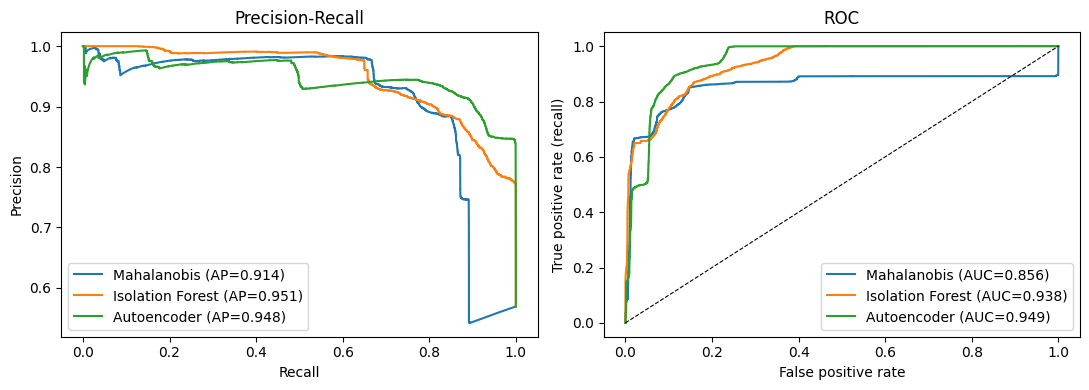

In [26]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_recall_curve, roc_curve, roc_auc_score, average_precision_score
import matplotlib.pyplot as plt

iso = IsolationForest(random_state=42, contamination="auto").fit(x_normal)

# One score per test row, oriented so HIGHER = more likely an attack
scores = {
    "Mahalanobis": d2_test,
    "Isolation Forest": -iso.decision_function(x_test_scaled),
    "Autoencoder": err_test,
}

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name, s in scores.items():
    prec, rec, _ = precision_recall_curve(y_test_binary, s)
    fpr, tpr, _ = roc_curve(y_test_binary, s)
    ax[0].plot(rec, prec, label=f"{name} (AP={average_precision_score(y_test_binary, s):.3f})")
    ax[1].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test_binary, s):.3f})")

ax[0].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall")
ax[1].set(xlabel="False positive rate", ylabel="True positive rate (recall)", title="ROC")
ax[1].plot([0, 1], [0, 1], "k--", linewidth=0.8)
for a in ax:
    a.legend()
plt.tight_layout()
plt.show()